# Задача №2: статистические модели прогнозирования

В notebook сравниваются ручные и автоматические статистические
методы из `statsforecast`. Выбор выполняется по rolling-origin
backtesting, вероятностным интервалам и анализу ошибок.

## Дизайн эксперимента

- Горизонт: 6 месяцев.
- 4 окна backtesting с шагом 6 месяцев.
- 9 отраслевых временных рядов.
- Метрики: MAE, RMSE, sMAPE и сезонный MASE.
- Интервалы: 80% и 95%.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from IPython.display import Image, display
import pandas as pd

REPORTS_DIR = ROOT / "reports" / "task2"
FIGURES_DIR = ROOT / "figures" / "task2"

from scripts.task2_statistical_models import (
    build_models,
    run_task2,
)

/usr/local/Caskroom/miniconda/base/envs/timeseries/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


## Код эксперимента

Конфигурация моделей хранится в воспроизводимом Python-модуле.
Полный расчет можно запустить из notebook, установив флаг ниже.
По умолчанию используются уже сохраненные результаты, поскольку
повторный backtesting занимает несколько минут.

In [2]:
build_models()

[SeasonalNaive,
 Naive,
 ARIMA_manual,
 AutoARIMA,
 ETS_manual,
 AutoETS,
 Theta,
 AutoTheta]

In [3]:
RUN_FULL_EXPERIMENT = False
if RUN_FULL_EXPERIMENT:
    run_task2()

## Загрузка результатов

Полный backtesting выполняется скриптом
`scripts/task2_statistical_models.py`. Notebook загружает готовые
артефакты, чтобы не повторять тяжелые расчеты при каждом открытии.

In [4]:
metrics = pd.read_csv(REPORTS_DIR / "model_metrics.csv")
industry_metrics = pd.read_csv(
    REPORTS_DIR / "model_metrics_by_industry.csv"
)
horizon_metrics = pd.read_csv(
    REPORTS_DIR / "model_metrics_by_horizon.csv"
)
diagnostics = pd.read_csv(REPORTS_DIR / "residual_diagnostics.csv")
fitted_diagnostics = pd.read_csv(
    REPORTS_DIR / "fitted_residual_diagnostics.csv"
)
tests = pd.read_csv(REPORTS_DIR / "model_comparison_tests.csv")
final_forecasts = pd.read_csv(REPORTS_DIR / "final_forecasts.csv")

## Сравнение моделей

In [5]:
metrics.round(3)

,model,mae,rmse,smape,mase,bias,coverage_80,coverage_95,mean_width_95,interval_score_95
0,Theta,42.657,60.411,8.407,0.719,13.161,0.940,0.995,361.251,364.012
1,AutoTheta,42.786,60.832,8.416,0.722,13.118,0.935,0.995,361.205,363.684
2,ARIMA_manual,46.981,71.012,8.838,0.758,16.817,0.963,1.000,395.830,395.830
3,SeasonalNaive,46.514,67.497,9.120,0.772,17.829,0.986,1.000,509.810,509.810
4,ETS_manual,46.721,66.665,9.277,0.777,10.072,0.958,0.995,381.147,382.056
5,AutoETS,50.134,90.429,9.377,0.802,8.033,0.907,0.981,332.445,443.699
6,AutoARIMA,52.237,78.719,9.338,0.809,21.900,0.954,1.000,410.384,410.384
7,Prophet_manual,74.103,102.698,13.319,1.202,63.222,0.755,0.935,358.182,401.205
8,Naive,74.338,108.534,14.698,1.271,3.569,0.972,1.000,965.345,965.345


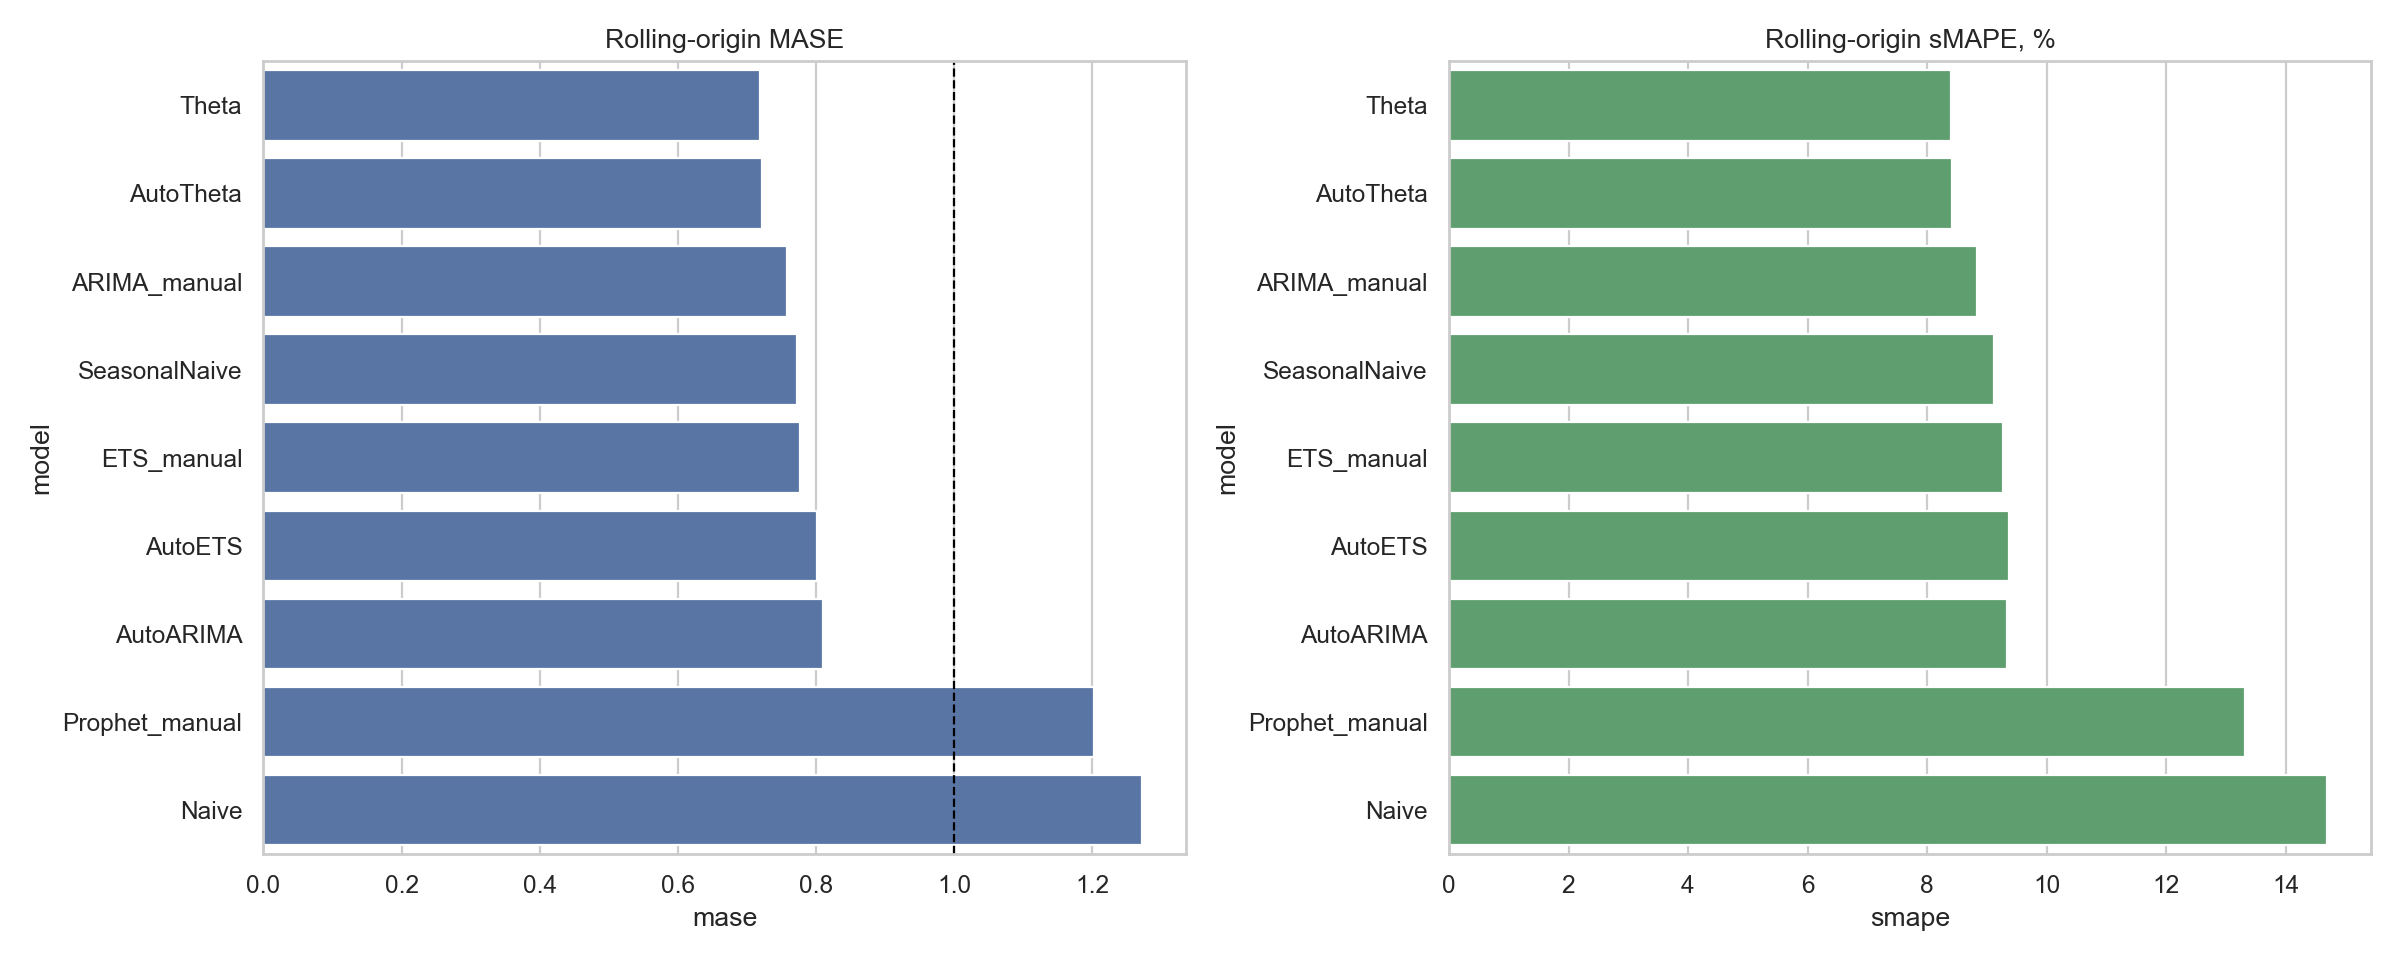

In [6]:
display(Image(filename=FIGURES_DIR / "model_metrics.png"))

`SeasonalNaive` является основным baseline. MASE меньше 1 означает,
что модель в среднем точнее сезонного наивного масштаба ошибок.

## Результаты по отраслям

In [7]:
industry_metrics.pivot(
    index="unique_id",
    columns="model",
    values="mase",
).round(3)

model,ARIMA_manual,AutoARIMA,AutoETS,AutoTheta,ETS_manual,Naive,Prophet_manual,SeasonalNaive,Theta
unique_id,,,,,,,,,
Construction,0.670,0.590,0.588,0.564,0.591,0.702,0.889,0.616,0.574
Education and Health Services,1.280,1.481,1.176,1.071,1.122,1.734,1.643,1.027,1.030
Financial Activities,0.693,0.676,0.779,0.785,0.716,1.107,0.805,0.772,0.784
Government,0.640,0.686,0.876,0.897,0.850,2.737,0.743,0.483,0.891
Information,0.644,0.631,0.636,0.663,0.687,0.817,0.826,0.781,0.662
Leisure and Hospitality,0.934,1.134,1.111,0.766,0.868,1.426,1.110,0.844,0.767
Manufacturing,0.584,0.534,0.649,0.458,0.777,0.998,2.300,0.970,0.467
Professional and Business Services,0.705,0.746,0.676,0.656,0.683,0.814,0.997,0.686,0.657
"Trade, Transportation, and Utilities",0.669,0.805,0.726,0.638,0.699,1.108,1.506,0.770,0.640


## Результаты по горизонту

In [8]:
horizon_metrics.pivot(
    index="horizon",
    columns="model",
    values="mase",
).round(3)

model,ARIMA_manual,AutoARIMA,AutoETS,AutoTheta,ETS_manual,Naive,Prophet_manual,SeasonalNaive,Theta
horizon,,,,,,,,,
1,0.622,0.814,0.662,0.548,0.691,1.292,1.066,0.766,0.546
2,0.767,0.842,0.823,0.847,0.811,1.336,1.209,0.843,0.841
3,0.675,0.711,0.840,0.826,0.831,1.202,1.240,0.844,0.818
4,0.692,0.969,0.679,0.682,0.683,1.800,0.954,0.741,0.665
5,1.032,0.903,1.097,0.751,0.933,1.153,1.330,0.713,0.750
6,0.757,0.616,0.712,0.677,0.712,0.846,1.413,0.725,0.695


## Последнее окно backtesting

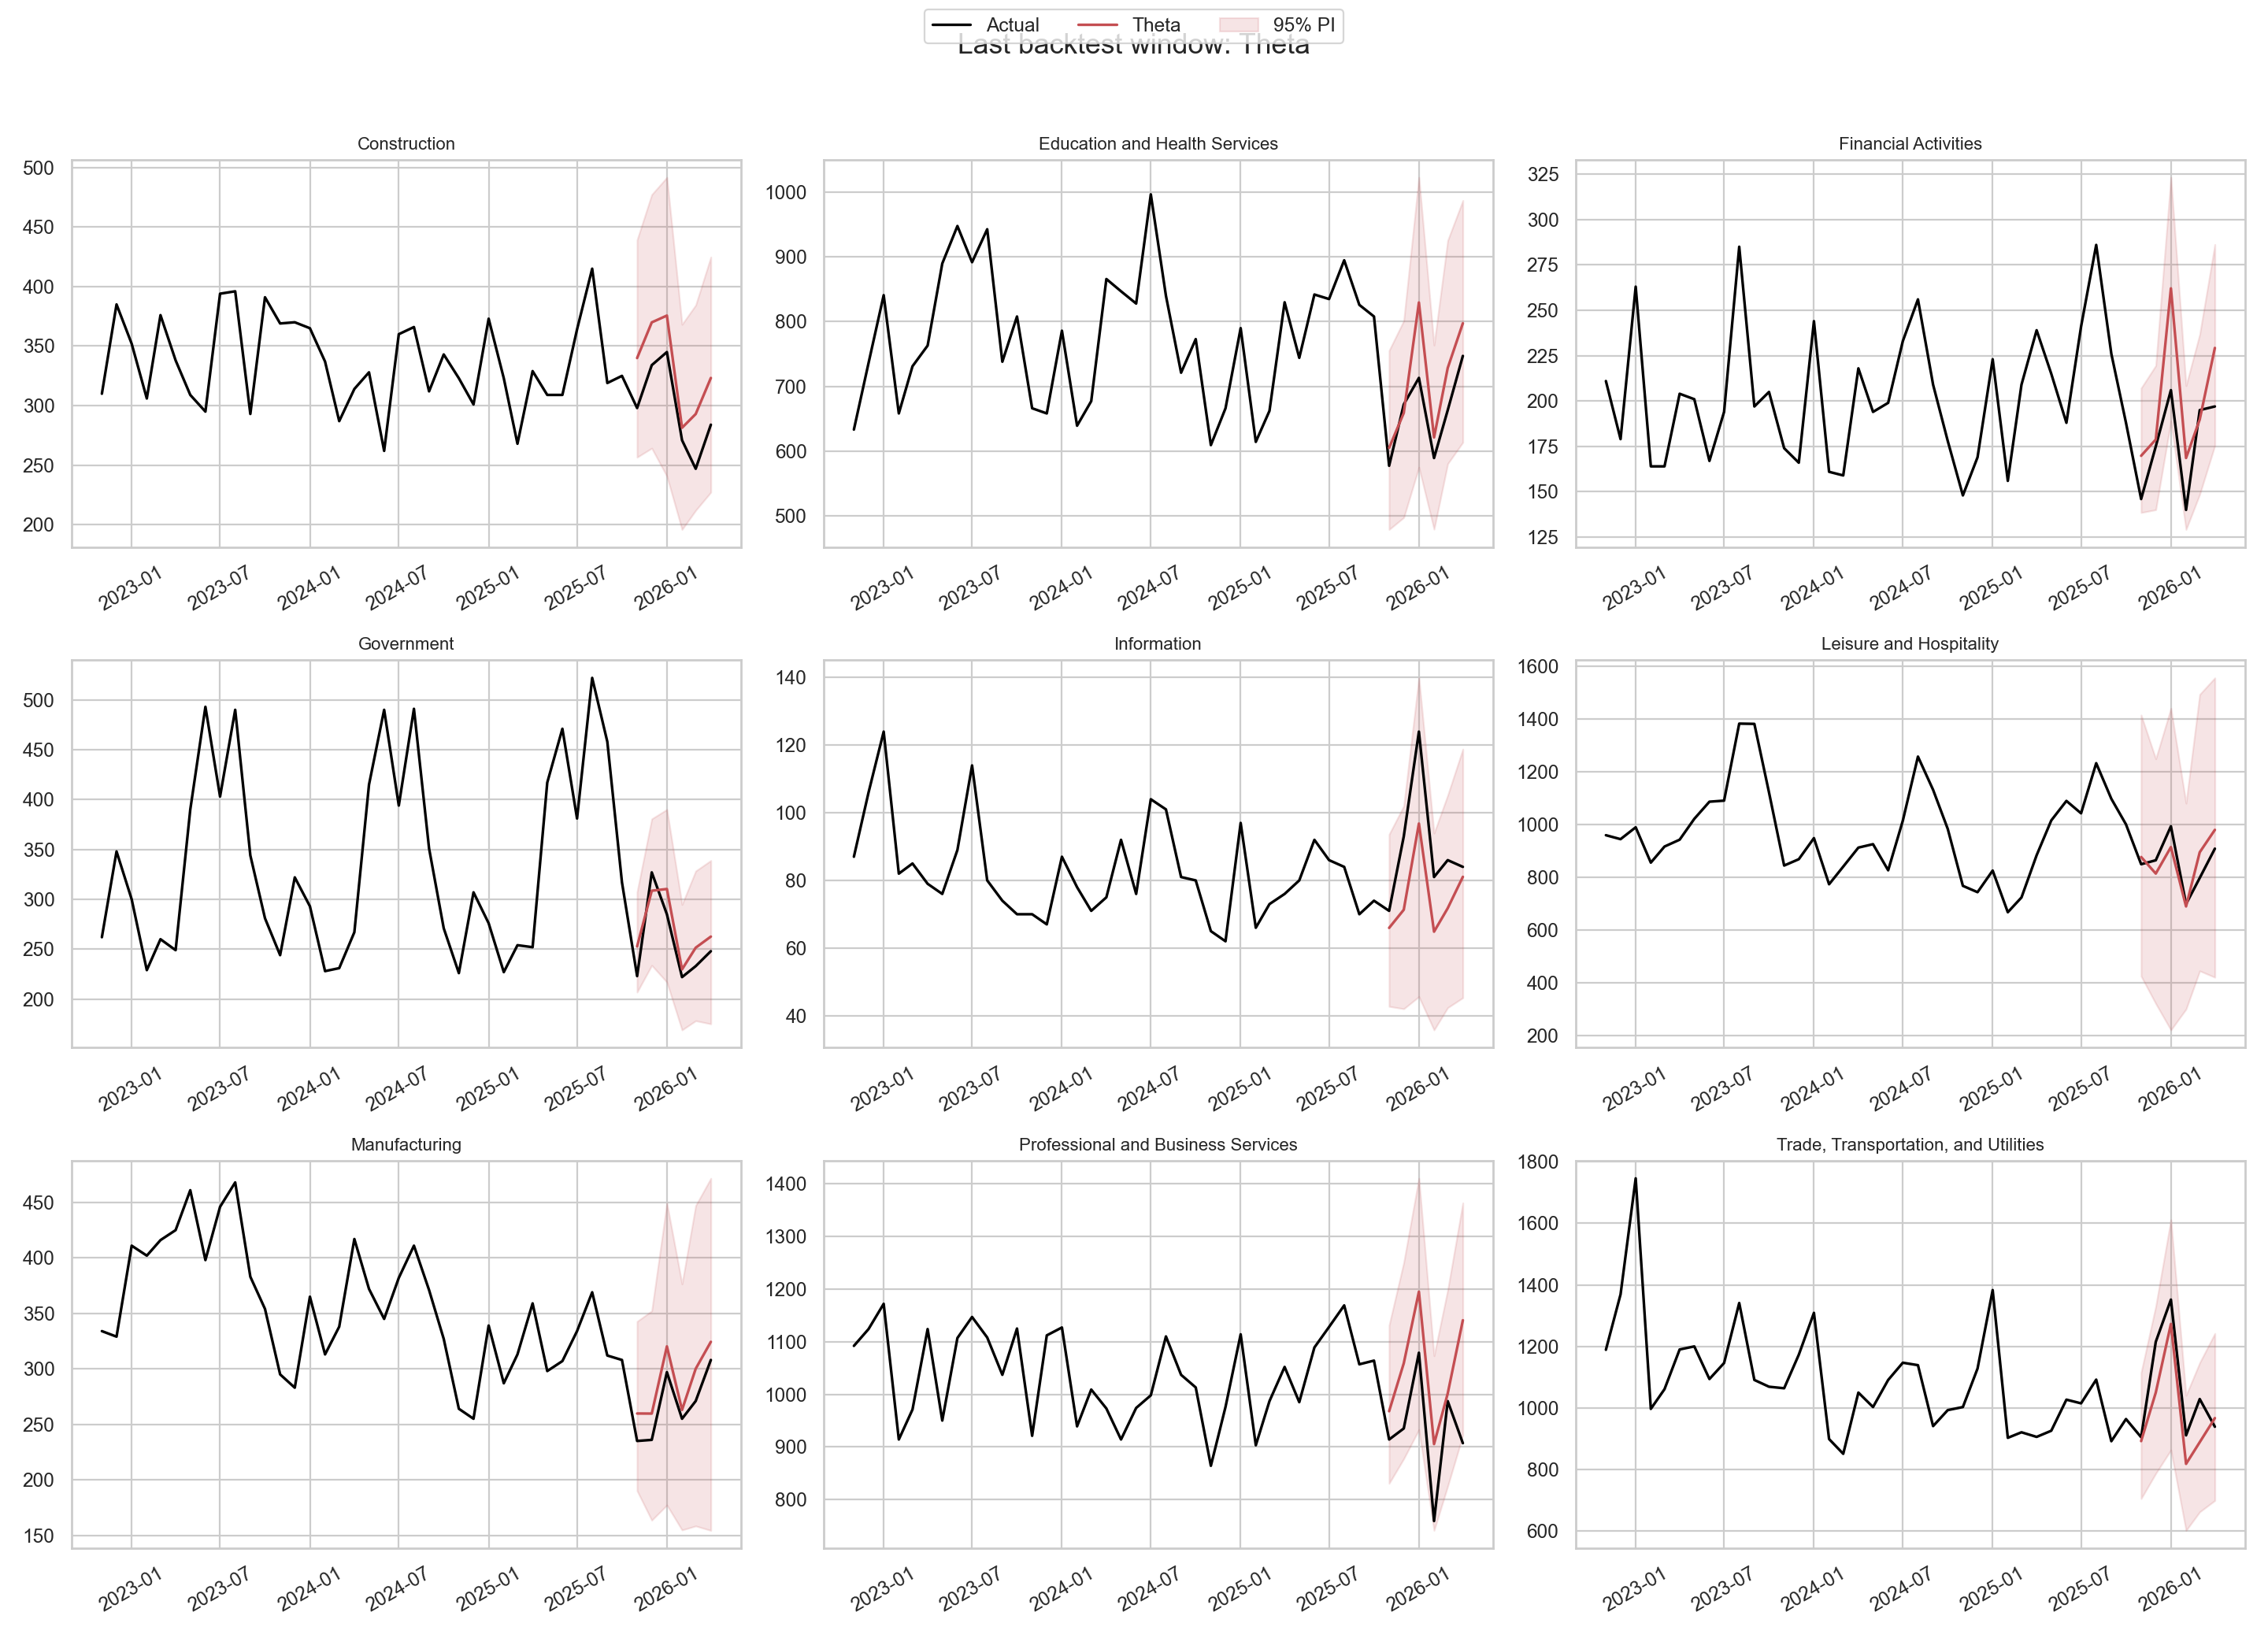

In [9]:
display(Image(filename=FIGURES_DIR / "best_model_last_window.png"))

## Вероятностные интервалы

In [10]:
metrics[
    ["model", "coverage_80", "coverage_95"]
].round(3)

,model,coverage_80,coverage_95
0,Theta,0.940,0.995
1,AutoTheta,0.935,0.995
2,ARIMA_manual,0.963,1.000
3,SeasonalNaive,0.986,1.000
4,ETS_manual,0.958,0.995
5,AutoETS,0.907,0.981
6,AutoARIMA,0.954,1.000
7,Prophet_manual,0.755,0.935
8,Naive,0.972,1.000


## Анализ ошибок и остатков

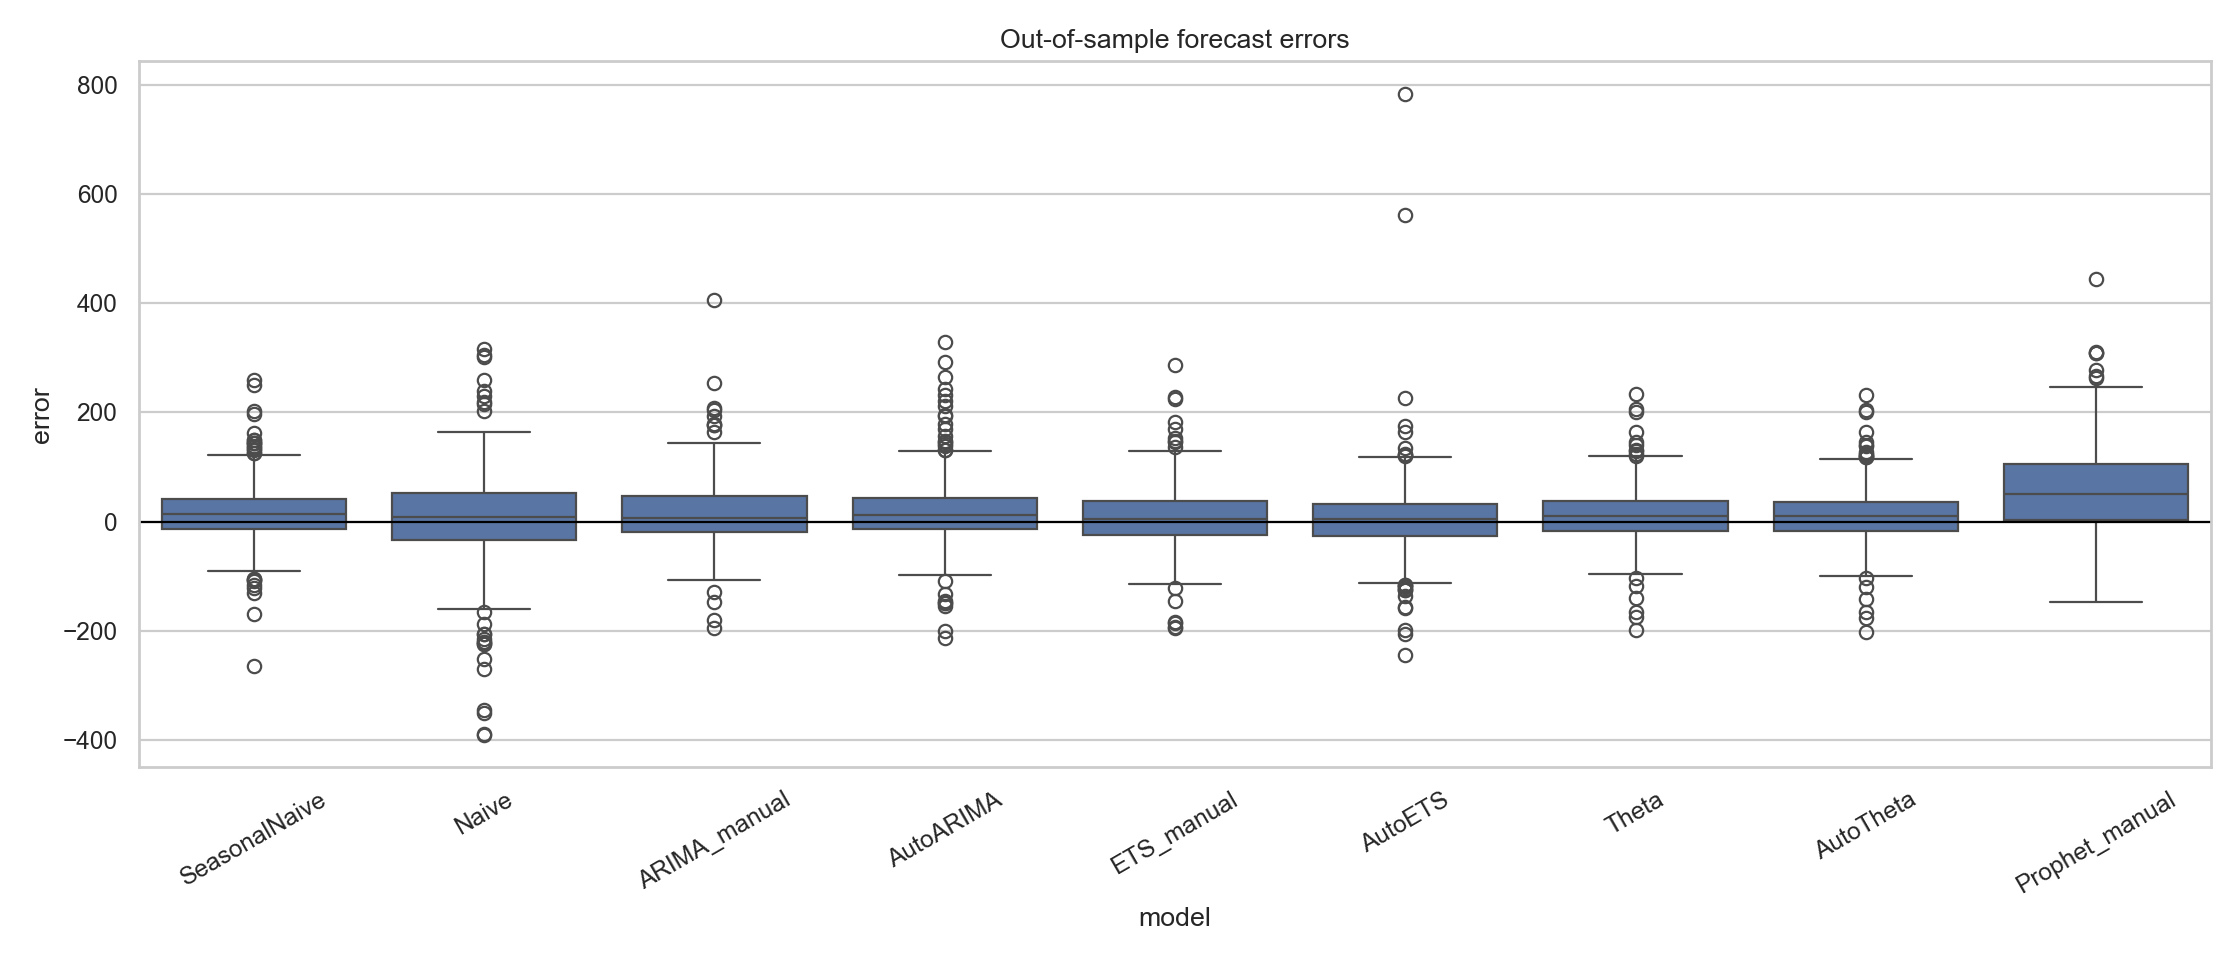

In [11]:
display(Image(filename=FIGURES_DIR / "forecast_error_boxplots.png"))

In [12]:
diagnostics.groupby("model").agg(
    mean_bias=("mean_error", "mean"),
    white_noise_share=("white_noise_5pct", "mean"),
    median_ljung_box_pvalue=("ljung_box_pvalue_lag6", "median"),
).round(3)

,mean_bias,white_noise_share,median_ljung_box_pvalue
model,,,
ARIMA_manual,16.817,0.889,0.368
AutoARIMA,21.900,0.667,0.240
AutoETS,8.033,0.889,0.350
AutoTheta,13.118,0.889,0.207
ETS_manual,10.072,0.778,0.185
Naive,3.569,0.778,0.334
Prophet_manual,63.222,0.889,0.317
SeasonalNaive,17.829,0.778,0.419
Theta,13.161,0.889,0.227


### Классические fitted residuals

In [13]:
fitted_diagnostics.groupby("model").agg(
    mean_residual=("mean_residual", "mean"),
    white_noise_share=("white_noise_5pct", "mean"),
    median_ljung_box_pvalue=("ljung_box_pvalue", "median"),
).round(3)

,mean_residual,white_noise_share,median_ljung_box_pvalue
model,,,
ARIMA_manual,1.900,0.778,0.272
AutoARIMA,0.737,0.889,0.887
AutoETS,-2.857,0.000,0.001
AutoTheta,0.249,0.111,0.001
ETS_manual,0.096,0.111,0.002
Naive,-0.068,0.000,0.000
Prophet_manual,-0.030,0.000,0.000
SeasonalNaive,-0.994,0.000,0.000
Theta,0.131,0.111,0.001


## Статистическое сравнение моделей

In [14]:
tests

,test,model_a,model_b,statistic,pvalue,pvalue_holm,significant_5pct
0,Friedman,all,all,49.704493,4.657418e-08,4.657418e-08,True
1,Wilcoxon_abs_error,Theta,SeasonalNaive,254.000000,1.101829e-01,4.407317e-01,False
2,Wilcoxon_abs_error,Theta,Naive,38.000000,9.602809e-08,7.682247e-07,True
3,Wilcoxon_abs_error,Theta,ARIMA_manual,316.000000,3.989446e-01,7.978892e-01,False
4,Wilcoxon_abs_error,Theta,AutoARIMA,268.000000,1.574641e-01,4.723923e-01,False
5,Wilcoxon_abs_error,Theta,ETS_manual,218.000000,3.587700e-02,2.152620e-01,False
6,Wilcoxon_abs_error,Theta,AutoETS,242.000000,7.840799e-02,3.920400e-01,False
7,Wilcoxon_abs_error,Theta,AutoTheta,330.500000,4.843348e-01,7.978892e-01,False
8,Wilcoxon_abs_error,Theta,Prophet_manual,147.000000,1.391928e-03,9.743493e-03,True


## Финальный шестимесячный прогноз

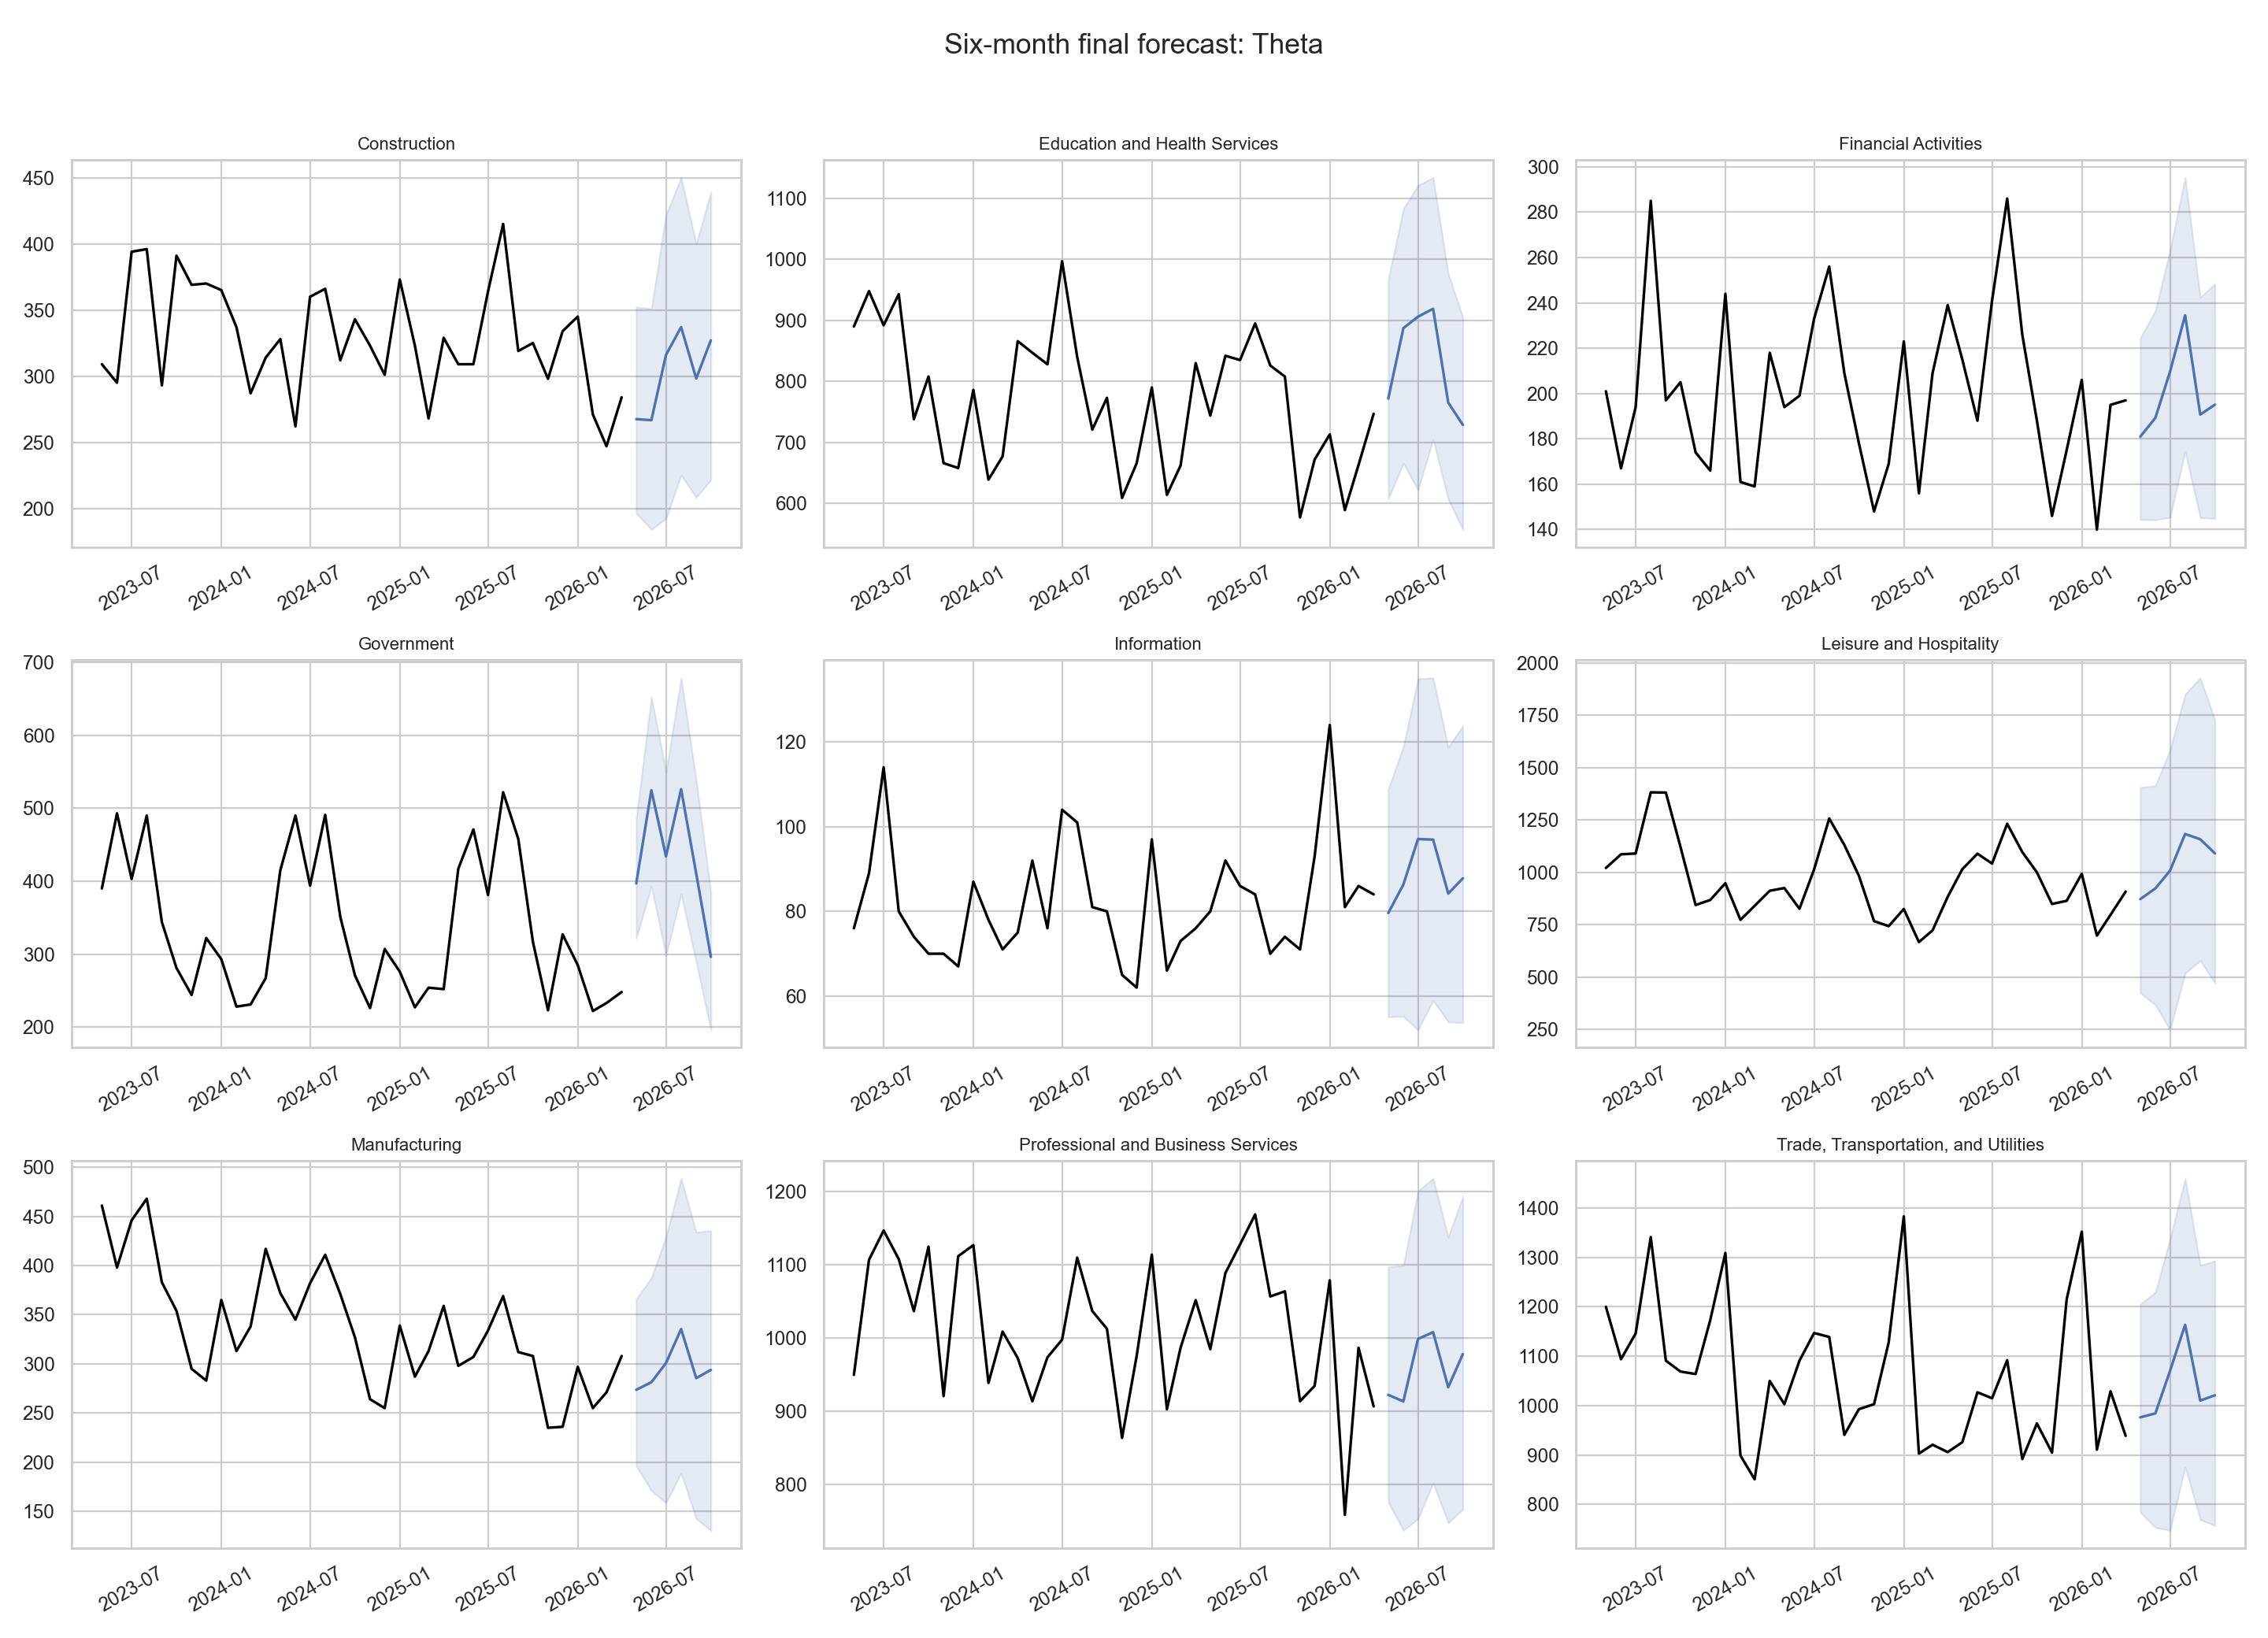

In [15]:
display(Image(filename=FIGURES_DIR / "final_forecast.png"))

In [16]:
final_forecasts.head(12)

,unique_id,ds,SeasonalNaive,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-80,SeasonalNaive-hi-95,Naive,Naive-lo-80,Naive-lo-95,...,AutoTheta,AutoTheta-lo-80,AutoTheta-hi-80,AutoTheta-lo-95,AutoTheta-hi-95,Prophet_manual,Prophet_manual-lo-80,Prophet_manual-hi-80,Prophet_manual-lo-95,Prophet_manual-hi-95
0,Construction,2026-05-01,309.0,214.40016,164.32202,403.59985,453.67798,284.0,190.639980,141.218190,...,266.75705,213.28564,331.67206,195.59550,351.50910,288.386077,224.217133,358.462161,196.003381,388.824654
1,Construction,2026-06-01,309.0,214.40016,164.32202,403.59985,453.67798,284.0,151.969010,82.076020,...,265.77680,203.69125,315.52954,183.09055,350.00864,287.861044,222.873177,357.341552,186.177237,391.612471
2,Construction,2026-07-01,364.0,269.40015,219.32202,458.59985,508.67798,284.0,122.295715,36.694637,...,314.71634,227.50923,379.11185,191.15819,420.71590,344.945599,276.604232,420.706210,246.309405,453.054929
3,Construction,2026-08-01,415.0,320.40015,270.32202,509.59985,559.67800,284.0,97.279976,-1.563636,...,335.39510,258.06403,396.42648,223.76282,448.41232,372.422010,303.748335,444.029054,281.699977,477.599983
4,Construction,2026-09-01,319.0,224.40016,174.32202,413.59985,463.67798,284.0,75.240660,-35.269850,...,296.49850,235.32703,364.81918,206.76389,397.94504,323.421466,252.814847,390.182784,221.577869,422.936071
5,Construction,2026-10-01,325.0,230.40016,180.32202,419.59985,469.67798,284.0,55.315605,-65.742600,...,324.99753,252.31017,401.61450,219.44695,436.88950,358.795158,300.823775,426.095331,267.772962,454.377184
6,Education and Health Services,2026-05-01,744.0,566.15770,472.01370,921.84230,1015.98630,747.0,575.696350,485.013700,...,772.86816,649.21850,922.98060,608.31104,968.85266,813.317071,689.268240,921.089573,632.840270,982.424511
7,Education and Health Services,2026-06-01,842.0,664.15770,570.01370,1019.84230,1113.98630,747.0,504.740080,376.495420,...,888.86140,732.19604,1009.94720,666.85510,1087.60460,895.570421,776.911163,1015.998158,695.216514,1080.857903
8,Education and Health Services,2026-07-01,835.0,657.15770,563.01370,1012.84230,1106.98630,747.0,450.293430,293.226440,...,908.07200,727.09400,1046.56790,627.13635,1124.74330,903.922551,791.307325,1028.800000,741.557208,1076.945989
9,Education and Health Services,2026-08-01,895.0,717.15770,623.01370,1072.84230,1166.98630,747.0,404.392760,223.027420,...,921.53670,751.76980,1049.79490,706.51160,1144.22160,908.919993,782.665441,1019.575110,722.853918,1086.387370


## Вывод по задаче №2

In [17]:
print((REPORTS_DIR / "task2_report.md").read_text(encoding="utf-8"))

# Задача №2: статистические методы прогнозирования

## Дизайн эксперимента

- Фреймворк: `statsforecast`.
- Горизонт одного прогноза: 6 месяцев.
- Rolling-origin backtesting: 4 окна с шагом 6 месяцев.
- Всего оценено 216 совпадающих прогнозов на модель.
- Метрики: MAE, RMSE, sMAPE и сезонный MASE.
- Вероятностные интервалы: 80% и 95%.

Горизонт совпадает с постановкой задачи №1. Неперекрывающиеся окна покрывают
последние 24 месяца и позволяют проверить модели в нескольких недавних
рыночных режимах без утечки будущих данных. Основная метрика — сезонный MASE,
поскольку масштабы увольнений существенно различаются между отраслями.

## Сравниваемые модели

- `SeasonalNaive(12)` — основной сезонный baseline.
- `Naive` — прогноз последним наблюдением.
- `ARIMA_manual` — ARIMA(1,1,1)(1,1,1)[12].
- `AutoARIMA` — автоматический выбор порядков по AICc.
- `ETS_manual` — фиксированная аддитивная ETS(A,A,A).
- `AutoETS` — автоматический выбор ETS-компонент.
- `Theta` — классическая сезонная Theta.
-